In [1]:
!pip install openpyxl

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings('ignore')

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [6]:
df = pd.read_csv('/content/data.csv', encoding='latin1')

print("Dataset Loaded Successfully!")

df.head()

Dataset Loaded Successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [9]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [10]:
print("Total Rows and Columns:", df.shape)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows and Columns: (541909, 8)
Total Rows: 541909
Total Columns: 8


In [11]:
print("Dataset Columns:")

for col in df.columns:
    print(col)

Dataset Columns:
InvoiceNo
StockCode
Description
Quantity
InvoiceDate
UnitPrice
CustomerID
Country


In [12]:
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [14]:
print("Missing Values:")

print(df.isnull().sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [15]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 5268


In [16]:
df.describe(include='all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,10/31/2011 14:41,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


In [17]:
print("Original Columns:")
print(df.columns.tolist())

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Original Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Shape:
(541909, 8)

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [18]:
df_clean = df.copy()

print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)

Original Dataset: (541909, 8)
Working Dataset: (541909, 8)


In [19]:
print("Duplicates Before Cleaning:",
      df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicates After Cleaning:",
      df_clean.duplicated().sum())

Duplicates Before Cleaning: 5268
Duplicates After Cleaning: 0


In [20]:
print("Missing Customer IDs:",
      df_clean['CustomerID'].isnull().sum())

df_clean = df_clean.dropna(subset=['CustomerID'])

print("After Removing Missing IDs:",
      df_clean.shape)

Missing Customer IDs: 135037
After Removing Missing IDs: (401604, 8)


In [21]:
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

print("After Removing Cancelled Transactions:",
      df_clean.shape)

After Removing Cancelled Transactions: (392732, 8)


In [22]:
df_clean = df_clean[
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
]

print("After Removing Invalid Transactions:",
      df_clean.shape)


After Removing Invalid Transactions: (392692, 8)


In [23]:
print("Final Dataset Shape:", df_clean.shape)

print("Missing Values:")
print(df_clean.isnull().sum())

df_clean.head()

Final Dataset Shape: (392692, 8)
Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [24]:
df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate'],
    errors='coerce'
)

print("InvoiceDate Converted Successfully!")

print(df_clean['InvoiceDate'].dtype)

InvoiceDate Converted Successfully!
datetime64[ns]


In [25]:
df_clean['TotalAmount'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

df_clean[['Quantity', 'UnitPrice', 'TotalAmount']].head()

,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [26]:
snapshot_date = (
    df_clean['InvoiceDate'].max()
    + pd.Timedelta(days=1)
)

print("Analysis Date:", snapshot_date)

Analysis Date: 2011-12-10 12:50:00


In [27]:
rfm = df_clean.groupby('CustomerID').agg({

    'InvoiceDate': lambda x: (
        snapshot_date - x.max()
    ).days,

    'InvoiceNo': 'nunique',

    'TotalAmount': 'sum'

})

rfm.rename(columns={

    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'

}, inplace=True)

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [28]:
print("RFM Analysis Completed!")

print("Total Customers:", len(rfm))

display(rfm.head(10))

RFM Analysis Completed!
Total Customers: 4338


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40


In [29]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [30]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

print("RFM Scores Assigned Successfully!")

RFM Scores Assigned Successfully!


In [31]:
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(int) +
    rfm['F_Score'].astype(int) +
    rfm['M_Score'].astype(int)
)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,5,7
12347.0,2,7,4310.00,5,5,5,15
12348.0,75,4,1797.24,2,4,4,10
12349.0,19,1,1757.55,4,1,4,9
12350.0,310,1,334.40,1,1,2,4
12352.0,36,8,2506.04,3,5,5,13
12353.0,204,1,89.00,1,1,1,3
12354.0,232,1,1079.40,1,1,4,6
12355.0,214,1,459.40,1,1,2,4


In [32]:
def segment_customer(row):

    if row['RFM_Score'] >= 13:
        return 'Champions'

    elif row['RFM_Score'] >= 10:
        return 'Loyal Customers'

    elif row['RFM_Score'] >= 7:
        return 'Potential Customers'

    elif row['RFM_Score'] >= 5:
        return 'At Risk'

    else:
        return 'Lost Customers'


rfm['Customer_Segment'] = rfm.apply(
    segment_customer,
    axis=1
)

print("Customer Segmentation Completed!")

Customer Segmentation Completed!


In [33]:
display(rfm.head(15))

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
CustomerID,,,,,,,,
12346.0,326,1,77183.60,1,1,5,7,Potential Customers
12347.0,2,7,4310.00,5,5,5,15,Champions
12348.0,75,4,1797.24,2,4,4,10,Loyal Customers
12349.0,19,1,1757.55,4,1,4,9,Potential Customers
12350.0,310,1,334.40,1,1,2,4,Lost Customers
12352.0,36,8,2506.04,3,5,5,13,Champions
12353.0,204,1,89.00,1,1,1,3,Lost Customers
12354.0,232,1,1079.40,1,1,4,6,At Risk
12355.0,214,1,459.40,1,1,2,4,Lost Customers


In [34]:
segment_counts = rfm['Customer_Segment'].value_counts()

print(segment_counts)

Customer_Segment
Potential Customers    1085
Loyal Customers        1012
Champions               929
At Risk                 765
Lost Customers          547
Name: count, dtype: int64


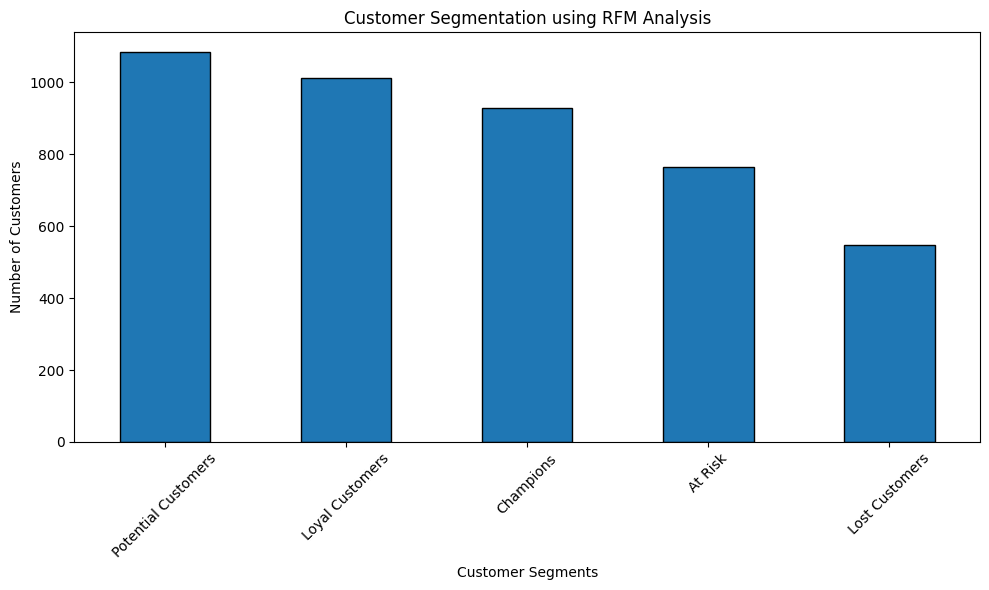

In [35]:
plt.figure(figsize=(10, 6))

segment_counts.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Customer Segmentation using RFM Analysis')
plt.xlabel('Customer Segments')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
rfm_features = rfm[['Recency', 'Frequency', 'Monetary']]

rfm_features.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [37]:
rfm_log = np.log1p(rfm_features)

print("Log Transformation Completed!")

rfm_log.head()

Log Transformation Completed!


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,5.789960,0.693147,11.253955
12347.0,1.098612,2.079442,8.368925
12348.0,4.330733,1.609438,7.494564
12349.0,2.995732,0.693147,7.472245
12350.0,5.739793,0.693147,5.815324


In [38]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

print("Data Standardized Successfully!")

Data Standardized Successfully!


In [39]:
inertia = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia.append(kmeans.inertia_)

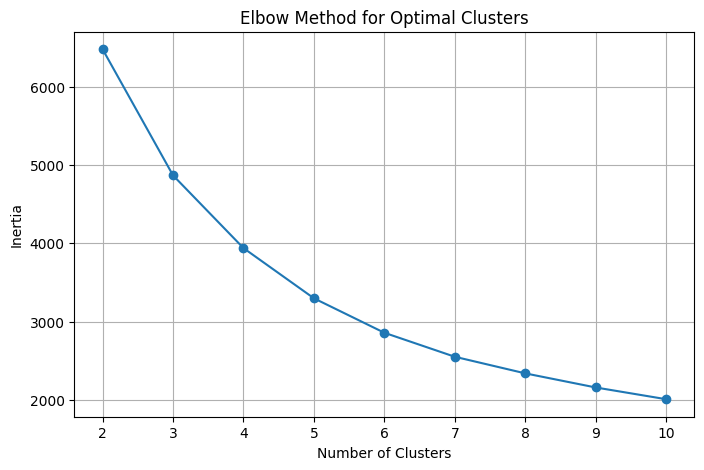

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.grid(True)
plt.show()

In [41]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print("K-Means Clustering Completed!")

K-Means Clustering Completed!


In [42]:
print("Customers in Each Cluster:")

print(rfm['Cluster'].value_counts().sort_index())

Customers in Each Cluster:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


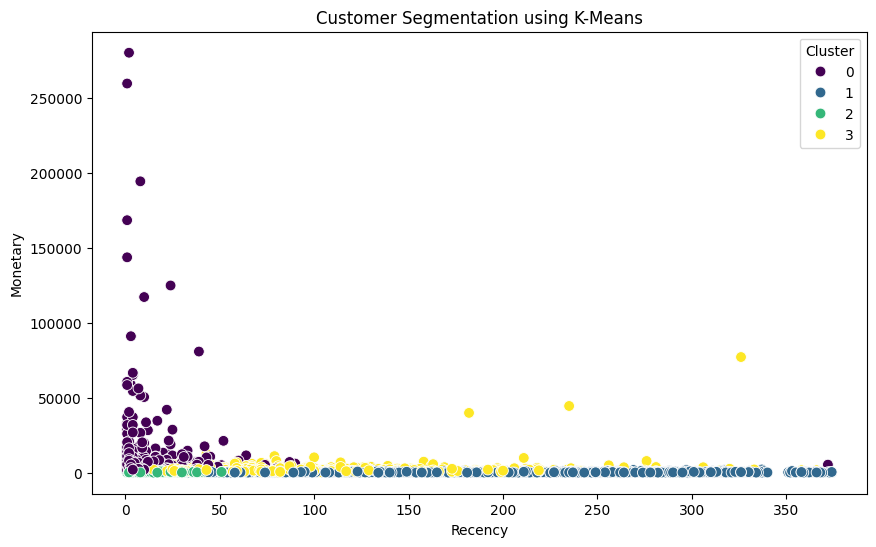

In [43]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Recency')
plt.ylabel('Monetary')

plt.show()

In [44]:
cluster_summary = rfm.groupby('Cluster').agg({

    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'

}).round(2)

display(cluster_summary)

,Recency,Frequency,Monetary
Cluster,,,
0,12.17,13.75,8088.02
1,181.51,1.32,341.00
2,17.70,2.19,557.32
3,71.64,4.08,1801.78


In [45]:
cluster_analysis = rfm.groupby('Cluster').agg(
    Total_Customers=('Recency', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean')
).round(2)

display(cluster_analysis)

,Total_Customers,Average_Recency,Average_Frequency,Average_Monetary
Cluster,,,,
0,713,12.17,13.75,8088.02
1,1622,181.51,1.32,341.00
2,837,17.70,2.19,557.32
3,1166,71.64,4.08,1801.78


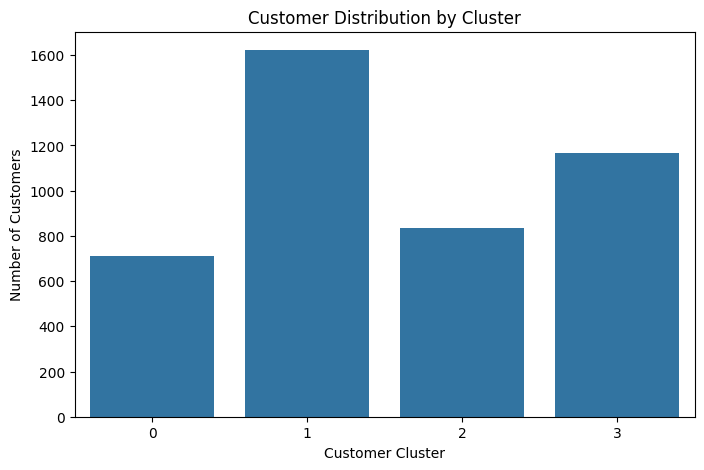

In [46]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x='Cluster'
)

plt.title('Customer Distribution by Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.show()

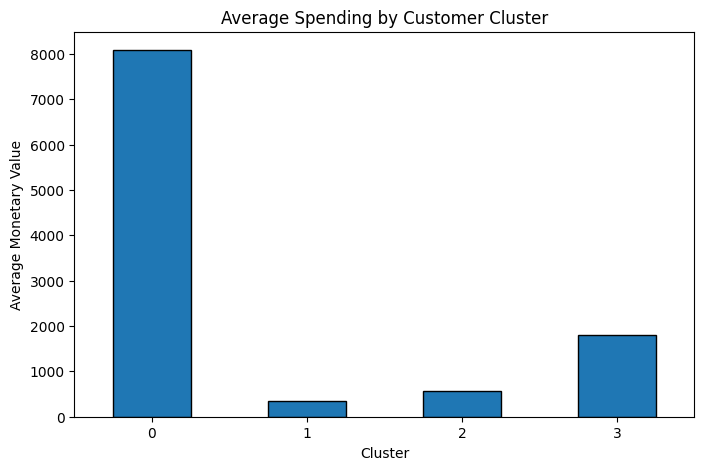

In [47]:
plt.figure(figsize=(8, 5))

cluster_analysis['Average_Monetary'].plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Average Spending by Customer Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Monetary Value')

plt.xticks(rotation=0)
plt.show()

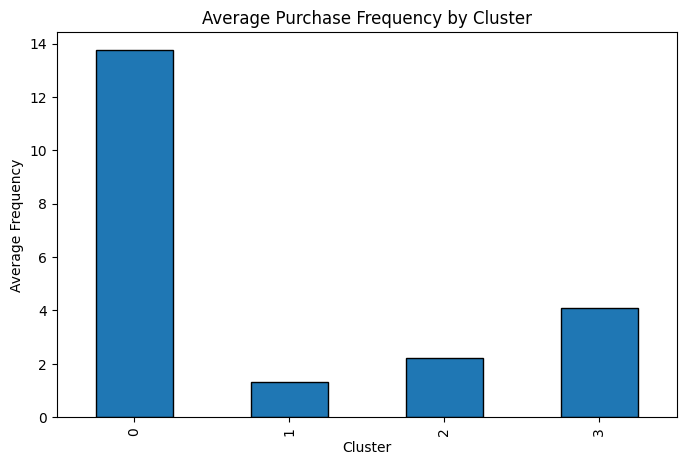

In [48]:
plt.figure(figsize=(8, 5))

cluster_analysis['Average_Frequency'].plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Average Purchase Frequency by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Frequency')

plt.show()

In [49]:
final_data = rfm.reset_index()

final_data.to_csv(
    'Customer_Segmentation_Results.csv',
    index=False
)

print("Customer Segmentation File Saved Successfully!")

Customer Segmentation File Saved Successfully!


In [50]:
from google.colab import files

files.download('Customer_Segmentation_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>